In [8]:
import os, sys
import math
import numpy as np
from datetime import timedelta
# sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath(os.path.join('..', 'modules_zeus')))
from modules_zeus.era5_cds import Era5CDSLoader, get_today
loader = Era5CDSLoader()

In [9]:
start_timestamp, end_timestamp, num_predict_hours = loader.sample_time_range()
print(start_timestamp, end_timestamp, num_predict_hours)
current_hour = np.random.randint(0, 24)
start = start_timestamp - get_today('h') + timedelta(hours=current_hour)
end = end_timestamp - get_today('h') + timedelta(hours=current_hour)
print(start.to_pytimedelta().total_seconds()/3600, end.to_pytimedelta().total_seconds()/3600, num_predict_hours)
print("T = ", math.ceil((end.to_pytimedelta().total_seconds()/3600) / 24) + 5)

2025-08-06 10:00:00 2025-08-06 23:00:00 14
-73.0 -60.0 14
T =  3


In [ ]:
def get_T2():
    start_timestamp, end_timestamp, num_predict_hours = loader.sample_time_range()
    current_hour = np.random.randint(0, 24)
    # Make the time-agnostic. Simulate reality, where time drifts.
    start = start_timestamp - get_today('h') + timedelta(hours=current_hour)
    end = end_timestamp - get_today('h') + timedelta(hours=current_hour)
    choice = end
    # t2 = math.ceil((end.to_pytimedelta().total_seconds()/3600) / 24) + 4
    hours = choice.to_pytimedelta().total_seconds()/3600
    t2 = math.ceil(hours/24) + 5    # starts from 5 days ago
    return t2

In [11]:
T2 = []
for _ in range(10000):
    t2 = get_T2()
    # if t2 > 0 : 
    T2.append(t2)
print(len(T2))

10000


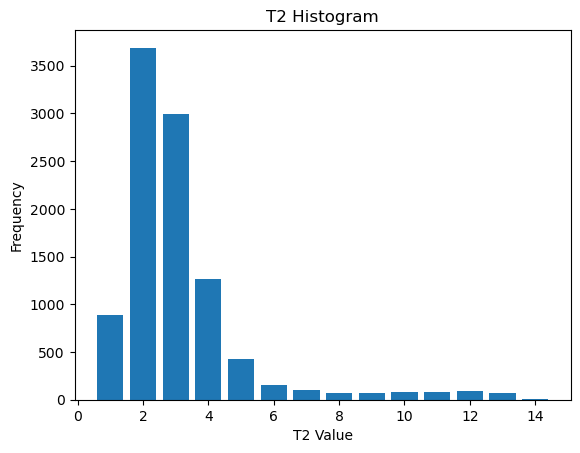

In [13]:
import matplotlib.pyplot as plt

plt.hist(T2, bins=range(min(T2), max(T2) + 2), align='left', rwidth=0.8)
plt.xlabel("T2 Value")
plt.ylabel("Frequency")
plt.title("T2 Histogram")
plt.show()